# 05E - Going further: the Wronskian

**MATH 331 - Differential Equations.** Lecture plan: after Sessions 11 and 12 (the Wronskian as an area; special functions; zeros that take turns).

**This notebook is optional.** It goes beyond what the course asks. Read notebook 05 first.

**References**
* [AD] W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): Section
  3.2 (Wronskian), Section 3.3 (Theorem 8, Remark 9), Section 4.2 (Theorem 6, the $n$-th order
  formula), Section 5.2 (Theorem 5).
* [AWH] G.B. Arfken, H.J. Weber, F.E. Harris, *Mathematical Methods for Physicists*, 7th ed.
  (Academic Press, 2013), Section 7.6: Wronskian and linear dependence (Examples 7.6.1-7.6.2), at
  most two independent solutions (eqs. 7.56-7.57), $W' = -PW$ (eqs. 7.60-7.63 and footnote 7), a
  second solution (eq. 7.67), Exercise 7.6.4.
* [DLMF] NIST *Digital Library of Mathematical Functions*, dlmf.nist.gov, eqs. 9.2.7 and 10.5.2.
* [L] J. Lebl, *Notes on Diffy Qs*: Example 2.3.1 ($e^x, e^{2x}, e^{3x}$ are independent, shown
  there without the Wronskian), Example 2.3.3.
* Sturm's separation theorem and Liouville's formula are classical results.

**What you will see**
1. The Wronskian as an **area** in the plane of states $(y, y')$, and Abel's theorem as a law for
   that area.
2. The Wronskian of exponentials: a classical determinant.
3. A warning: for functions that are not solutions of one equation, $W = 0$ proves nothing.
4. Abel's theorem for solutions nobody can write down: Airy and Bessel functions.
5. Consequences: never three independent solutions; a second solution of Legendre's equation;
   the zeros of two solutions take turns (Sturm).
6. A look ahead: systems, and equations of order $n$.
7. For constant coefficients: why the formulas of notebook 06 give **all** the solutions, and how
   they agree with Abel's theorem.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: rk4, wronskian_values).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The Wronskian is an area

At each $x$, a solution is described by its **state** $(y, y')$: a point of a plane (the initial
conditions are exactly a state). The Wronskian is the determinant of the two states

$$ \mathbf u_1 = \begin{pmatrix} y_1 \\ y_1' \end{pmatrix}, \qquad \mathbf u_2 = \begin{pmatrix} y_2 \\ y_2' \end{pmatrix}, $$

that is, the **signed area of the parallelogram** they span (video R07).

* $W \ne 0$: the two arrows are not parallel, and every state is a combination of them (Section 3
  of notebook 05, said with a picture).
* $W = 0$: the arrows are parallel and the parallelogram is flat.

The picture follows the parallelogram as $x$ moves, for $y'' + 2\zeta\,y' + y = 0$, starting from
$y_1(0) = 1$, $y_1'(0) = 0$ and $y_2(0) = 0$, $y_2'(0) = 1$, so $W(0) = 1$. Abel's theorem, with
$p(x) = 2\zeta$ (the whole coefficient of $y'$), predicts $W(x) = e^{-2\zeta x}$.

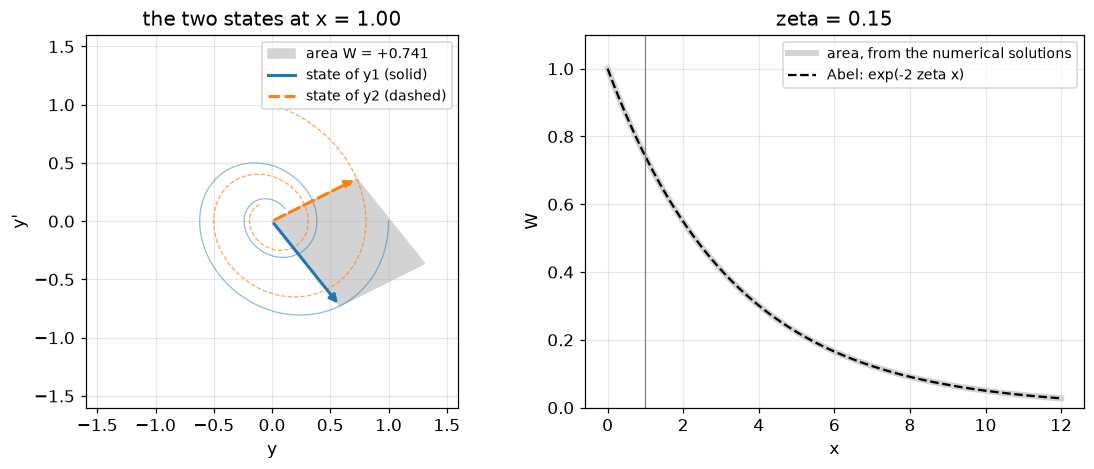

In [2]:
X_LONG = 12.0
STEP = 0.005
SQUARE = (-1.6, 1.6)
TWO_PANELS = (10.5, 4.4)


def two_states(zeta):
    # y1, y1', y2, y2' for y'' + 2 zeta y' + y = 0, computed numerically (no formula is used)
    def system(point, state):
        return np.array([state[1], -2 * zeta * state[1] - state[0], state[3], -2 * zeta * state[3] - state[2]])

    points, values = ol.rk4(system, (0.0, X_LONG), [1.0, 0.0, 0.0, 1.0], STEP)
    return points, values[:, 0], values[:, 1], values[:, 2], values[:, 3]


def plot_parallelogram(x_now=1.0, zeta=0.15):
    points, a, da, b, db = two_states(zeta)
    index = min(np.searchsorted(points, x_now), points.size - 1)
    area = ol.wronskian_values(a, da, b, db)
    first, second = np.array([a[index], da[index]]), np.array([b[index], db[index]])
    corners = np.array([[0.0, 0.0], first, first + second, second])
    fig, (plane, right) = plt.subplots(1, 2, figsize=TWO_PANELS)
    plane.plot(a, da, "-", color="tab:blue", linewidth=0.8, alpha=0.5)
    plane.plot(b, db, "--", color="tab:orange", linewidth=0.8, alpha=0.7)
    plane.fill(corners[:, 0], corners[:, 1], color="lightgray", label=f"area W = {area[index]:+.3f}")
    for arrow, colour, style, name in ((first, "tab:blue", "-", "state of y1 (solid)"),
                                       (second, "tab:orange", "--", "state of y2 (dashed)")):
        plane.annotate("", xy=arrow, xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": colour, "lw": 2,
                                                                 "linestyle": style})
        plane.plot([], [], linestyle=style, color=colour, linewidth=2, label=name)
    plane.set_xlim(*SQUARE)
    plane.set_ylim(*SQUARE)
    plane.set_aspect("equal")
    plane.set_xlabel("y")
    plane.set_ylabel("y'")
    plane.set_title(f"the two states at x = {points[index]:.2f}")
    plane.legend(loc="upper right")
    right.plot(points, area, "-", linewidth=4, color="lightgray", label="area, from the numerical solutions")
    right.plot(points, np.exp(-2 * zeta * points), "--", color="black", label="Abel: exp(-2 zeta x)")
    right.axvline(points[index], color="gray", linewidth=0.8)
    right.set_ylim(0.0, 1.1)
    right.set_xlabel("x")
    right.set_ylabel("W")
    right.set_title(f"zeta = {zeta:g}")
    right.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_parallelogram()

*The plot shows* two panels. Left: the plane of states, with two arrows from the origin (solid
for $y_1$, dashed for $y_2$) and the grey parallelogram they span, at $x = 1$; the thin curves
are the paths the two arrow tips follow, spiralling into the origin. Right: the area of the
parallelogram against $x$ (thick grey line) with Abel's prediction $e^{-0.3x}$ (black dashes) on
top of it, falling from 1 towards 0; a vertical line marks $x = 1$.

**Sliders.** Before moving them: without damping ($\zeta = 0$), what happens to the shape of the
parallelogram, and to its area?

In [3]:
interact(plot_parallelogram,
         x_now=FloatSlider(value=1.0, min=0.0, max=X_LONG, step=0.1, description="x", continuous_update=False),
         zeta=FloatSlider(value=0.15, min=0.0, max=0.5, step=0.05, description="zeta", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='x', max=12.0), FloatSlider(...

(The arrows rotate and the shape changes, but the area stays exactly 1. With no $y'$ term,
**areas in the plane of states are conserved**: the simplest case of Liouville's theorem of
mechanics. With damping, the area shrinks at the relative rate $p(x)$, the coefficient of $y'$.)

## 2. Exponentials: the Vandermonde determinant

For $y_k = e^{r_kx}$ every derivative brings down a factor $r_k$, so each column of the
Wronskian matrix carries a factor $e^{r_kx}$:

$$ W[e^{r_1x},\dots,e^{r_nx}] = e^{(r_1+\dots+r_n)x}\,
\det\begin{pmatrix}1 & \cdots & 1\\ r_1 & \cdots & r_n\\ \vdots & & \vdots\\ r_1^{n-1} & \cdots & r_n^{n-1}\end{pmatrix}
= e^{(r_1+\dots+r_n)x}\prod_{i<j}(r_j - r_i) . $$

The determinant is the classical **Vandermonde determinant**. So **exponentials with different
rates are always independent**. For two of them, $W = (r_2 - r_1)\,e^{(r_1 + r_2)x}$: the formula
behind notebook 06. Lebl's Example 2.3.1 shows in three other ways that $e^x, e^{2x}, e^{3x}$ are
independent; with the Wronskian, $W = (2-1)(3-1)(3-2)\,e^{6x} = 2e^{6x}$.

In [4]:
x = sp.symbols("x", positive=True)
rates = sp.symbols("r1:4")
general = sp.factor(sp.simplify(sp.wronskian([sp.exp(rate * x) for rate in rates], x)))
print("W[e^(r1 x), e^(r2 x), e^(r3 x)] =", general)

three = sp.simplify(sp.wronskian([sp.exp(x), sp.exp(2 * x), sp.exp(3 * x)], x))
dependent = sp.simplify(sp.wronskian([sp.exp(x), sp.exp(-x), sp.cosh(x)], x))
print("W[e^x, e^(2x), e^(3x)] =", three, "   (Lebl, Example 2.3.1)")
print("W[e^x, e^(-x), cosh x] =", dependent, "   (dependent: e^x + e^(-x) = 2 cosh x; Arfken, Example 7.6.2)")

assert three == 2 * sp.exp(6 * x) and dependent == 0

W[e^(r1 x), e^(r2 x), e^(r3 x)] = -(r1 - r2)*(r1 - r3)*(r2 - r3)*exp(r1*x)*exp(r2*x)*exp(r3*x)
W[e^x, e^(2x), e^(3x)] = 2*exp(6*x)    (Lebl, Example 2.3.1)
W[e^x, e^(-x), cosh x] = 0    (dependent: e^x + e^(-x) = 2 cosh x; Arfken, Example 7.6.2)


## 3. A warning: $W = 0$ proves nothing for arbitrary functions

For **any** two differentiable functions: if $W \ne 0$ at some point, they are independent [AD,
Section 3.2; AWH, Section 7.6]. (If $C_1f_1 + C_2f_2 = 0$ for all $x$, differentiate: the pair
$(C_1, C_2)$ solves a homogeneous system whose determinant is $W$.)

**The converse is false.** The classical example: $f_1 = t^3$ and $f_2 = |t|^3$. Both have a
continuous derivative, $W = 0$ everywhere, and yet they are **independent** on $(-1, 1)$:
$f_2 = f_1$ for $t > 0$ and $f_2 = -f_1$ for $t < 0$, so no single constant works. And the
Wronskian of arbitrary functions may vanish at single points: $W[t, t^2] = t^2$.

Adkins and Davidson warn: if the Wronskian is zero, you cannot conclude that the functions are
dependent. For two **solutions of one linear equation** none of this can happen: that is Abel's
theorem. (Why can $t^3$ and $|t|^3$ not both solve one equation $y'' + py' + qy = 0$ with
continuous coefficients? At $t = 0$ both have $y = y' = 0$, and by uniqueness the only such
solution is $y = 0$.)

W[t^3, |t|^3] = 0    at a few points: [0, 0, 0, 0]
W[t, t^2] = t**2
Adkins-Davidson 3.2:  W[t, 1/t] = -2/t    W[e^(2t), e^(-t)] = -3*exp(t)


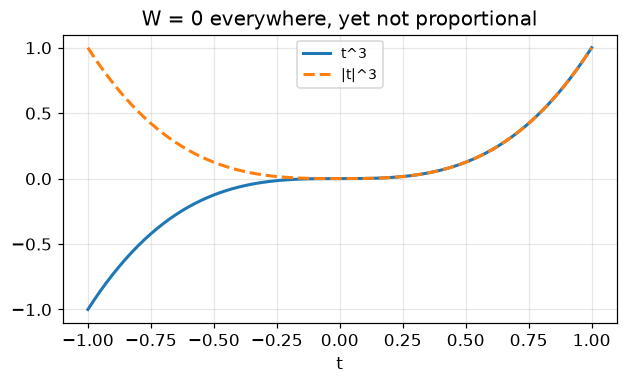

In [5]:
t = sp.symbols("t", real=True)
cube, absolute_cube = t ** 3, sp.Abs(t) ** 3
zero = sp.simplify(cube * sp.diff(absolute_cube, t) - sp.diff(cube, t) * absolute_cube)
print("W[t^3, |t|^3] =", zero, "   at a few points:", [zero.subs(t, value) for value in (-2, -0.5, 0.5, 2)])
print("W[t, t^2] =", sp.wronskian([t, t ** 2], t))
print("Adkins-Davidson 3.2:  W[t, 1/t] =", sp.simplify(sp.wronskian([t, 1 / t], t)),
      "   W[e^(2t), e^(-t)] =", sp.simplify(sp.wronskian([sp.exp(2 * t), sp.exp(-t)], t)))

FIGURE_SIZE = (6.5, 3.4)
points = np.linspace(-1.0, 1.0, 401)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, points ** 3, "-", linewidth=2, label="t^3")
ax.plot(points, np.abs(points) ** 3, "--", linewidth=2, label="|t|^3")
ax.set_xlabel("t")
ax.set_title("W = 0 everywhere, yet not proportional")
ax.legend(loc="upper center")
plt.show()

assert zero == 0

*The plot shows* the two functions on $(-1, 1)$: $t^3$ (solid) goes from $-1$ to 1 through the
origin; $|t|^3$ (dashed) coincides with it on the right half and is its mirror image, positive,
on the left half. They are equal on one side and opposite on the other.

## 4. Abel's theorem for functions we cannot write down

The **Airy equation** $y'' - x\,y = 0$ (optics, quantum mechanics) has no solutions in terms of
elementary functions; its standard solutions are called $\mathrm{Ai}$ and $\mathrm{Bi}$. Here
$p = 0$, so by Abel their Wronskian is **constant**; the constant is $1/\pi$ [DLMF, 9.2.7].

**Bessel's equation** $x^2y'' + x\,y' + (x^2 - \nu^2)\,y = 0$ (vibrating drums, heat in cylinders):
in standard form $p = 1/x$, so $W = K/x$; for the standard pair, $W[J_\nu, Y_\nu] = \dfrac{2}{\pi x}$
[DLMF, 10.5.2], whatever $\nu$.

SciPy knows these functions and their derivatives: we check both predictions.

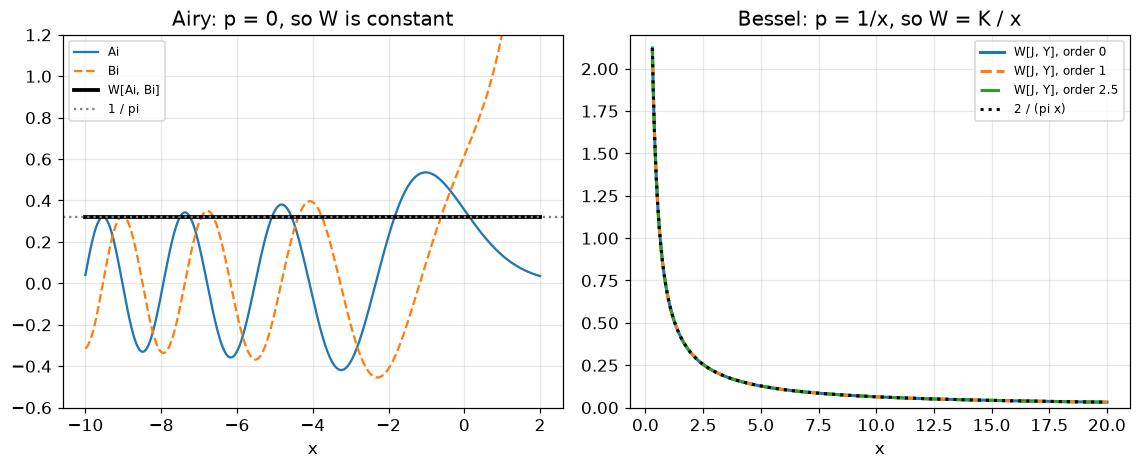

largest |W[Ai, Bi] - 1/pi| = 2.6e-15


In [6]:
from scipy.special import airy, jv, jvp, yv, yvp       # special functions and their derivatives

AIRY_RANGE = (-10.0, 2.0)
BESSEL_RANGE = (0.3, 20.0)
ORDERS = (0, 1, 2.5)
ORDER_STYLES = ("-", "--", "-.")
N_POINTS = 600

airy_points = np.linspace(*AIRY_RANGE, N_POINTS)
ai, ai_prime, bi, bi_prime = airy(airy_points)
airy_wronskian = ol.wronskian_values(ai, ai_prime, bi, bi_prime)
bessel_points = np.linspace(*BESSEL_RANGE, N_POINTS)

fig, (left, right) = plt.subplots(1, 2, figsize=TWO_PANELS)
left.plot(airy_points, ai, "-", label="Ai")
left.plot(airy_points, bi, "--", label="Bi")
left.plot(airy_points, airy_wronskian, "-", color="black", linewidth=2.5, label="W[Ai, Bi]")
left.axhline(1 / np.pi, linestyle=":", color="gray", label="1 / pi")
left.set_ylim(-0.6, 1.2)
left.set_xlabel("x")
left.set_title("Airy: p = 0, so W is constant")
left.legend(loc="upper left", fontsize=8)
for order, style in zip(ORDERS, ORDER_STYLES):
    bessel_wronskian = ol.wronskian_values(jv(order, bessel_points), jvp(order, bessel_points),
                                           yv(order, bessel_points), yvp(order, bessel_points))
    right.plot(bessel_points, bessel_wronskian, linestyle=style, linewidth=2, label=f"W[J, Y], order {order}")
    assert np.allclose(bessel_wronskian, 2 / (np.pi * bessel_points))
right.plot(bessel_points, 2 / (np.pi * bessel_points), ":", color="black", linewidth=2, label="2 / (pi x)")
right.set_ylim(0.0, 2.2)
right.set_xlabel("x")
right.set_title("Bessel: p = 1/x, so W = K / x")
right.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

print("largest |W[Ai, Bi] - 1/pi| =", f"{np.max(np.abs(airy_wronskian - 1 / np.pi)):.1e}")
assert np.allclose(airy_wronskian, 1 / np.pi)

*The plot shows* two panels. Left: the Airy functions, both oscillating faster and faster towards
the left ($\mathrm{Ai}$ solid, $\mathrm{Bi}$ dashed, which grows on the right), and their
Wronskian, a perfectly horizontal black line at $1/\pi \approx 0.318$. Right: the Wronskians of
the Bessel functions of orders 0, 1 and 2.5: three curves that cannot be told apart, all lying
on the dotted curve $2/(\pi x)$.

**When $p$ is not continuous.** Abel's theorem needs $p$ continuous on the interval. The equation
$y'' - \dfrac2x y' + \dfrac{2}{x^2}y = 0$ has the solutions $x$ and $x^2$, with $W = x^2$: zero at
$x = 0$, exactly where $p = -2/x$ is not defined. On $x > 0$ and on $x < 0$ separately $W \ne 0$,
as the theorem says [AWH, Section 7.6, footnote 7].

## 5. Consequences of Abel's theorem

### 5.1 Never three independent solutions [AWH, eqs. 7.56-7.57]

Let $y_1, y_2, y_3$ all solve $y'' + py' + qy = 0$. Fix a point $x_0$. The three states
$u_j = (y_j(x_0), y_j'(x_0))$ are three vectors in a plane, so there are constants $c_1, c_2, c_3$,
not all zero, with $c_1u_1 + c_2u_2 + c_3u_3 = 0$. Then
$y = c_1y_1 + c_2y_2 + c_3y_3$ is a solution with $y(x_0) = y'(x_0) = 0$, so $y = 0$ everywhere
by uniqueness: three solutions are always dependent, and the solutions form a space of
dimension exactly 2.

(Consistently, their 3 x 3 Wronskian is zero: its third row, $y_j'' = -p\,y_j' - q\,y_j$, is
$-p$ times the second row minus $q$ times the first. But remember Section 3: a zero Wronskian
alone would not have been a proof.)

### 5.2 A second solution of Legendre's equation

Reduction of order (notebook 05, Section 6) on **Legendre's equation** with $n = 1$:
$(1 - x^2)\,y'' - 2x\,y' + 2y = 0$, which has the solution $y_1 = x$. On $(-1, 1)$,
$p = \dfrac{-2x}{1 - x^2}$, so $e^{-\int p} = \dfrac{1}{1 - x^2}$, and the recipe gives

$$ y_2 = x\int \frac{dx}{x^2\,(1 - x^2)} = \frac{x}{2}\ln\frac{1 + x}{1 - x} - 1 , $$

the *Legendre function of the second kind* $Q_1$.

In [7]:
z = sp.symbols("z")                           # the variable of Legendre's equation, between -1 and 1
abel = 1 / (1 - z ** 2)
antiderivative = -1 / z + sp.atanh(z)         # of abel / z^2 (artanh z = (1/2) ln((1 + z)/(1 - z)))
second = sp.expand(z * antiderivative)
print("check of the antiderivative:", sp.simplify(sp.diff(antiderivative, z) - abel / z ** 2))
print("y2 =", second)
legendre = sp.simplify((1 - z ** 2) * sp.diff(second, z, 2) - 2 * z * sp.diff(second, z) + 2 * second)
print("(1 - z^2) y2'' - 2 z y2' + 2 y2 =", legendre)
assert legendre == 0

check of the antiderivative: 0
y2 = z*atanh(z) - 1


(1 - z^2) y2'' - 2 z y2' + 2 y2 = 0


### 5.3 Sturm's separation theorem: the zeros take turns

> **Theorem.** If $y_1, y_2$ are independent real solutions of $y'' + py' + qy = 0$ on an
> interval, then between two consecutive zeros of $y_1$ there is **exactly one** zero of $y_2$.

*Proof.* By Abel, $W$ never vanishes, so it keeps one sign. At a zero $a$ of $y_1$,
$W(a) = -y_1'(a)\,y_2(a)$: so $y_2(a) \ne 0$ and $y_1'(a) \ne 0$. At two consecutive zeros $a < b$
of $y_1$ the slopes $y_1'(a)$ and $y_1'(b)$ have opposite signs (the graph crosses the axis once
going up, once going down). Since $W(a)$ and $W(b)$ have the same sign, $y_2(a)$ and $y_2(b)$ have
opposite signs: $y_2$ has a zero between them. Exchanging the roles of $y_1$ and $y_2$, it cannot
have two. $\square$

Sine and cosine take turns crossing zero. So do the Airy functions, whose zeros are not equally
spaced. The slider mixes them: $\;y_\theta = \cos\theta\,\mathrm{Ai} + \sin\theta\,\mathrm{Bi}$ is
another solution, independent of $\mathrm{Ai}$ when $\sin\theta \ne 0$ (their Wronskian is
$\sin\theta/\pi$).

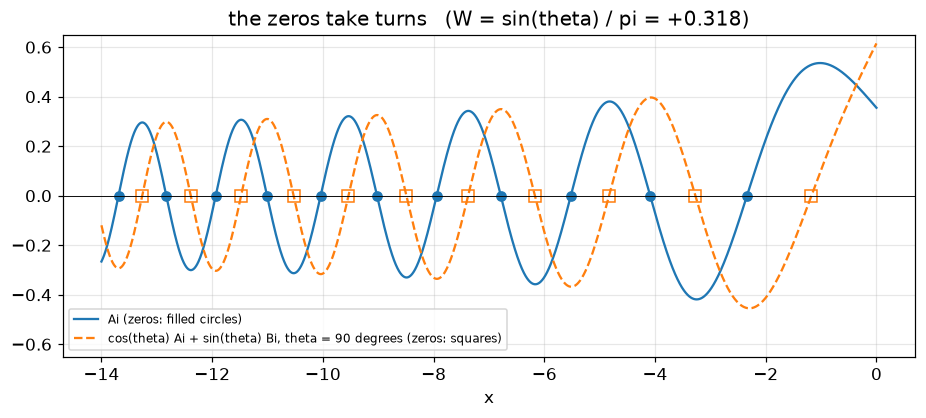

In [8]:
STURM_RANGE = (-14.0, 0.0)
WIDE_FIGURE = (10.0, 3.8)


def zeros_of(points, values):
    # zeros of a sampled function: changes of sign, refined by a straight line between two samples
    before = np.nonzero(np.sign(values[:-1]) * np.sign(values[1:]) < 0)[0]
    return points[before] - values[before] * (points[before + 1] - points[before]) / (values[before + 1] - values[before])


def plot_sturm(angle=90.0):
    points = np.linspace(*STURM_RANGE, 4001)
    ai, _, bi, _ = airy(points)
    theta = np.radians(angle)
    mixed = np.cos(theta) * ai + np.sin(theta) * bi
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(points, ai, "-", color="tab:blue", label="Ai (zeros: filled circles)")
    ax.plot(points, mixed, "--", color="tab:orange", label=f"cos(theta) Ai + sin(theta) Bi, theta = {angle:.0f} degrees (zeros: squares)")
    ax.plot(zeros_of(points, ai), 0 * zeros_of(points, ai), "o", color="tab:blue")
    ax.plot(zeros_of(points, mixed), 0 * zeros_of(points, mixed), "s", markerfacecolor="none", color="tab:orange",
            markersize=8)
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_ylim(-0.65, 0.65)
    ax.set_xlabel("x")
    ax.set_title(f"the zeros take turns   (W = sin(theta) / pi = {np.sin(theta) / np.pi:+.3f})")
    ax.legend(loc="lower left", fontsize=8)
    plt.show()


plot_sturm()

*The plot shows* two oscillating curves on $-14 \le x \le 0$: $\mathrm{Ai}$ (solid, zeros marked
by filled circles) and $\mathrm{Bi}$ (dashed, zeros marked by open squares). Along the axis the
marks alternate: circle, square, circle, square, ... although the spacing gets wider towards the
right.

**Slider.** Before moving it: what happens to the squares as the angle goes to 0 or to 180
degrees?

In [9]:
interact(plot_sturm, angle=FloatSlider(value=90.0, min=0.0, max=180.0, step=5.0, description="theta",
                                       continuous_update=False));

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='theta', max=180.0, step=5....

(They move onto the circles: at 0 and 180 degrees the two solutions are proportional, $W = 0$,
and the theorem, which needs independence, no longer applies.)

## 6. Looking ahead: systems, and order $n$

**Systems.** Write $y'' + py' + qy = 0$ as $\mathbf u' = A(x)\,\mathbf u$ with the state
$\mathbf u = (y, y')$ and the matrix $A = \begin{pmatrix} 0 & 1 \\ -q & -p \end{pmatrix}$. If $\Phi$
is the matrix whose columns are the states of $y_1$ and $y_2$, then $W = \det\Phi$, and Abel's
theorem is the 2 x 2 case of **Liouville's formula**

$$ \frac{d}{dx}\det\Phi = (\operatorname{tr}A)\,\det\Phi, \qquad \operatorname{tr}A = -p , $$

which holds for any linear system and comes back in the unit on systems.

**Order $n$.** For $y^{(n)} + a_{n-1}(x)\,y^{(n-1)} + \dots + a_0(x)\,y = 0$ the Wronskian of $n$
solutions satisfies $W' = -a_{n-1}(x)\,W$ (Liouville's formula above). For constant coefficients
this is $W = K\,e^{-a_{n-1}x}$ [AD, Section 4.2, Theorem 6]. Example: Lebl's Example 2.3.3,
$y''' - 3y'' - y' + 3y = 0$, has the solutions $e^{3x}, e^{x}, e^{-x}$ and $a_2 = -3$, so
$W = K e^{3x}$; the Vandermonde formula gives $K = (1-3)(-1-3)(-1-1) = -16$.

In [10]:
solutions = [sp.exp(3 * x), sp.exp(x), sp.exp(-x)]
residuals = [sp.simplify(sp.diff(y, x, 3) - 3 * sp.diff(y, x, 2) - sp.diff(y, x) + 3 * y) for y in solutions]
third_order = sp.simplify(sp.wronskian(solutions, x))
print("residuals:", residuals, "   W =", third_order)

p, q = sp.symbols("p q")
print("trace of the matrix A:", sp.Matrix([[0, 1], [-q, -p]]).trace())
assert residuals == [0, 0, 0] and third_order == -16 * sp.exp(3 * x)

residuals: [0, 0, 0]    W = -16*exp(3*x)
trace of the matrix A: -p


## 7. Constant coefficients: why the formulas give all the solutions

Notebook 06 finds the solutions of $a\,y'' + b\,y' + c\,y = 0$ by trying $e^{rx}$. Trying
produces solutions; does it produce **all** of them? Here is an argument with no guessing. Write
$D$ for the derivative. Because the coefficients are constants, the operator factors like the
polynomial:

$$ aD^2 + bD + c = a\,(D - r_1)(D - r_2), \qquad r_1 + r_2 = -\tfrac ba, \quad r_1r_2 = \tfrac ca . $$

The building block is

$$ (D - r)\big[e^{rx}u\big] = r\,e^{rx}u + e^{rx}u' - r\,e^{rx}u = e^{rx}\,u' , $$

that is, $(D - r)\,y = e^{rx}\,(e^{-rx}y)'$. Solve the equation in **two first-order steps**: put
$z = (D - r_2)\,y$, so that $(D - r_1)\,z = 0$.

1. $(D - r_1)\,z = 0$ means $(e^{-r_1x}z)' = 0$: $\;z = K_1e^{r_1x}$.
2. $(D - r_2)\,y = K_1e^{r_1x}$ means $(e^{-r_2x}y)' = K_1e^{(r_1 - r_2)x}$. Integrate:
   * if $r_1 \ne r_2$: $\;e^{-r_2x}y = \dfrac{K_1}{r_1 - r_2}e^{(r_1 - r_2)x} + K_2$, so
     $y = C_1e^{r_1x} + C_2e^{r_2x}$;
   * if $r_1 = r_2 = r$: $\;e^{-rx}y = K_1x + K_2$, so $y = (C_1 + C_2x)\,e^{rx}$.

Every step was an equivalence, so **every** solution has this form: a direct proof of Lebl's
Theorem 2.2.1. The factor $x$ of the repeated root is not magic: it is the integral of a
constant. The argument works unchanged for complex roots.

In [11]:
r, r_1, r_2, a_0 = sp.symbols("r r_1 r_2 a")
u_function, y_function = sp.Function("u")(x), sp.Function("y")(x)


def shifted(rate, function):
    # (D - rate) applied to a function of x
    return sp.diff(function, x) - rate * function


block = sp.simplify(shifted(r, sp.exp(r * x) * u_function) - sp.exp(r * x) * sp.diff(u_function, x))
print("(D - r)[exp(r x) u] - exp(r x) u' =", block)
print("a (D - r1)(D - r2) y =", sp.expand(a_0 * shifted(r_1, shifted(r_2, y_function))))
assert block == 0

(D - r)[exp(r x) u] - exp(r x) u' = 0
a (D - r1)(D - r2) y = a*r_1*r_2*y(x) - a*r_1*Derivative(y(x), x) - a*r_2*Derivative(y(x), x) + a*Derivative(y(x), (x, 2))


## 8. Constant coefficients and Abel's theorem agree

Abel's theorem predicts $W = K\,e^{-bx/a}$ for any two solutions of $a\,y'' + b\,y' + c\,y = 0$
[AD, Section 3.3, Theorem 8 and Remark 9]. In each of the three cases of notebook 06 the
Wronskian of the two basic solutions contains $e^{(r_1 + r_2)x}$, and $r_1 + r_2 = -b/a$:

| Roots | Solutions | $W$ |
|---|---|---|
| $r_1 \ne r_2$ real | $e^{r_1x},\ e^{r_2x}$ | $(r_2 - r_1)\,e^{(r_1 + r_2)x} = (r_2 - r_1)\,e^{-bx/a}$ |
| $r$ repeated | $e^{rx},\ x\,e^{rx}$ | $e^{2rx} = e^{-bx/a}$ |
| $\alpha \pm i\beta$ | $e^{\alpha x}\cos\beta x,\ e^{\alpha x}\sin\beta x$ | $\beta\,e^{2\alpha x} = \beta\,e^{-bx/a}$ |

Two independent routes, the same answer: the **sum** of the roots fixes how the Wronskian
changes. With $b = 0$ (no $y'$ term) it is constant.

The numerical check uses a small trick: the derivative of a solution is again a solution
(differentiate the equation), so `ol.constant_coefficient_solution` can give $y'$ as well as $y$.

In [12]:
CASES = ((1, -6, 8), (1, 2, 1), (1, -6, 13), (2, 3, 5))        # the three cases of notebook 06, and one more
check_points = np.linspace(0.0, 2.0, 201)

for a_value, b_value, c_value in CASES:
    y_first = ol.constant_coefficient_solution(check_points, a_value, b_value, c_value, 1, 0)       # y(0) = 1, y'(0) = 0
    y_second = ol.constant_coefficient_solution(check_points, a_value, b_value, c_value, 0, 1)      # y(0) = 0, y'(0) = 1
    # y'' = -(b y' + c y) / a gives the initial data of the derivatives
    dy_first = ol.constant_coefficient_solution(check_points, a_value, b_value, c_value, 0, -c_value / a_value)
    dy_second = ol.constant_coefficient_solution(check_points, a_value, b_value, c_value, 1, -b_value / a_value)
    computed = ol.wronskian_values(y_first, dy_first, y_second, dy_second)                          # W(0) = 1
    gap = np.max(np.abs(computed / np.exp(-b_value * check_points / a_value) - 1))
    first_root, second_root = ol.characteristic_roots(a_value, b_value, c_value)
    print(f"a, b, c = {a_value}, {b_value}, {c_value}:  r1 + r2 = {(first_root + second_root).real:+.2f} = -b/a;  "
          f"largest relative difference between W and exp(-b x / a): {gap:.0e}")
    assert gap < 1e-10

symbols = sp.symbols("alpha beta", real=True)
print("W[exp(alpha x) cos(beta x), exp(alpha x) sin(beta x)] =",
      sp.simplify(sp.wronskian([sp.exp(symbols[0] * x) * sp.cos(symbols[1] * x), sp.exp(symbols[0] * x) * sp.sin(symbols[1] * x)], x)))

a, b, c = 1, -6, 8:  r1 + r2 = +6.00 = -b/a;  largest relative difference between W and exp(-b x / a): 2e-14
a, b, c = 1, 2, 1:  r1 + r2 = -2.00 = -b/a;  largest relative difference between W and exp(-b x / a): 2e-15
a, b, c = 1, -6, 13:  r1 + r2 = +6.00 = -b/a;  largest relative difference between W and exp(-b x / a): 9e-16
a, b, c = 2, 3, 5:  r1 + r2 = -1.50 = -b/a;  largest relative difference between W and exp(-b x / a): 7e-16


W[exp(alpha x) cos(beta x), exp(alpha x) sin(beta x)] = beta*exp(2*alpha*x)


## 9. Summary

| Statement | Formula | Where |
|---|---|---|
| Wronskian | $W = y_1y_2' - y_1'y_2$ | [AD 3.2], [AWH 7.6] |
| Any initial data can be matched | exactly when $W(x_0) \ne 0$ | notebook 05, Section 3 |
| Geometric meaning | signed area spanned by the two states | Section 1 |
| Ratio | $(y_2/y_1)' = W/y_1^2$ | notebook 05, Section 4 |
| Exponentials | $W = e^{(\sum r_k)x}\prod_{i<j}(r_j - r_i)$ | Section 2 |
| **Abel** | $W(x) = W(x_0)\,e^{-\int p}$: never zero, or always zero | [AD 3.3, 5.2], [AWH eq. 7.63] |
| Second solution | $y_2 = y_1\int e^{-\int p}/y_1^2$ | [L, Exercise 2.1.7 at the end of the chapter], [AWH eq. 7.67] |
| Sturm | the zeros of two independent solutions take turns | Section 5.3 |

## 10. Problems

Ordinary problems, without automatic checks.

1. *(Arfken, Exercise 7.6.4)* Show that if $W[y_1, y_2] = 0$ on an interval where $y_1 \ne 0$, then
   $y_2 = c\,y_1$. (Use the ratio formula.)
2. Explain with the picture of Section 1 why, for $y'' + q(x)\,y = 0$, the parallelogram may
   change shape but never its area. What changes if a term $p\,y'$ with $p > 0$ is added?
3. Use Sturm's theorem to prove that every solution of $y'' + y = 0$ that is not zero has exactly
   one zero in every interval $[a, a + \pi)$.
4. *(Adkins and Davidson, Section 3.3, Exercise 18)* For $e^{r_1t}$ and $e^{r_2t}$ with
   $r_1 \ne r_2$: find the equation $y'' + by' + cy = 0$ they solve, their Wronskian, and the
   constant $K$ in $W = Ke^{-bt}$.
5. With the factorisation of Section 7, solve $y'' - 2r\,y' + r^2y = 0$ step by step and show
   that every solution is $(C_1 + C_2x)\,e^{rx}$.
6. Show that if $b^2 < 4ac$ every solution of $ay'' + by' + cy = 0$ that is not zero has
   infinitely many zeros, exactly $\pi/\beta$ apart. Compare with Sturm's theorem.

<details>
<summary>Final answers (after trying)</summary>

1. $(y_2/y_1)' = W/y_1^2 = 0$, so the ratio is a constant.
2. With $p = 0$ Abel gives $W' = 0$. With $p > 0$ the area shrinks: $W' = -pW$.
3. $\sin(x - a)$ is a solution with consecutive zeros at $a$ and $a + \pi$. Any solution
   independent of it has exactly one zero strictly between them; a solution proportional to it
   has the zero $a$ and no other in $[a, a + \pi)$.
4. $b = -(r_1 + r_2)$, $c = r_1r_2$, $W = (r_2 - r_1)\,e^{(r_1 + r_2)t}$, $K = r_2 - r_1$.
5. $z = (D - r)\,y$ solves $(D - r)\,z = 0$: $z = K_1e^{rx}$. Then $(e^{-rx}y)' = K_1$, so
   $y = (K_1x + K_2)\,e^{rx}$.
6. The solution is $A\,e^{\alpha x}\cos(\beta x - \gamma)$, zero exactly where the cosine is.

</details>